# Hurricane Milton


This notebook generates figures for the SatRain manuscript.

## Observation overview

In [ ]:
1

In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path

from argos.plotting import make_latlon_area
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

In [2]:
from argos.data.dataset import ArgosData

In [3]:
from pansat.geometry import LonLatRect

lon_min = -85
lon_max = -75
lat_min = 23
lat_max = 33

roi = LonLatRect(lon_min, lat_min, lon_max, lat_max)
area = make_latlon_area(
    lon_min,
    lat_min,
    lon_max,
    lat_max,
    800,
    800
)

area_5 = make_latlon_area(
    lon_min,
    lat_min,
    lon_max,
    lat_max,
    (lon_max - lon_min) / 0.05,
    (lat_max - lat_min) / 0.05,
)

In [4]:
from pansat.download.providers.data_provider import ALL_PROVIDERS
ALL_PROVIDERS;

In [5]:
from pansat.time import TimeRange

start_time = np.datetime64("2024-10-10T00:30:00")
end_time = np.datetime64("2024-10-10T01:30:00")
time_range = TimeRange(start_time, end_time)

In [6]:
ds = ArgosData(
    "/gdata2/simon/argus/training_data"
)
ds.load_input_data(start_time)

[16:25:14] INFO     Loaded cached index for 'gprof_gmi' from                                        ]8;id=13982260;file:///home/simon/src/argus/src/argos/data/dataset.py\dataset.py]8;;\:]8;id=13982261;file:///home/simon/src/argus/src/argos/data/dataset.py#1220\1220]8;;\
                    '/gdata2/simon/argus/training_data/.argos/indices/gprof_gmi.nc' (5640 stores).                 

AttributeError: 'Dataset' object has no attribute 'longitude'

In [ ]:
ds.reference_meta

In [8]:
from pansat.utils import resample_data
from pansat.products.satellite.ncei import cmorph_8km_30min
recs = cmorph_8km_30min.get(time_range)
res_cmorph = resample_data(recs[0].open()[{"time": 0}][["cmorph"]], area, radius_of_influence=10e3)

[16:02:33] WARNING  JAXA Earth API not available. Download and install the JAXA Earth API for Python  ]8;id=13352631;file:///home/simon/src/pansat/pansat/download/providers/gportal.py\gportal.py]8;;\:]8;id=13352632;file:///home/simon/src/pansat/pansat/download/providers/gportal.py#26\26]8;;\
                    from https://data.earth.jaxa.jp/api/python/ to use GPORTAL provider.                           

           WARNING  Found table named                                                                  ]8;id=13352639;file:///home/simon/src/pansat/pansat/catalog/index.py\index.py]8;;\:]8;id=13352640;file:///home/simon/src/pansat/pansat/catalog/index.py#268\268]8;;\
                    'reanalysis.era5_surface_hourly_10m_u_component_of_wind_10m_v_component_of_wind_2m             
                    _temperature_sea_surface_temperature_-158_-54_-128_-21' in database but could not              
                    load find a corresponding pansat product.                                                      

           WARNING  Found table named 'satellite.goes.l1b_goes16_rad_c04_conus' in database but could  ]8;id=13352645;file:///home/simon/src/pansat/pansat/catalog/index.py\index.py]8;;\:]8;id=13352646;file:///home/simon/src/pansat/pansat/catalog/index.py#268\268]8;;\
                    not load find a corresponding pansat product.                                                  

           WARNING  Found table named 'reanalysis.merra.m2i3nvasm' in database but could not load find ]8;id=13352651;file:///home/simon/src/pansat/pansat/catalog/index.py\index.py]8;;\:]8;id=13352652;file:///home/simon/src/pansat/pansat/catalog/index.py#268\268]8;;\
                    a corresponding pansat product.                                                                

           WARNING  Found table named                                                                  ]8;id=13352657;file:///home/simon/src/pansat/pansat/catalog/index.py\index.py]8;;\:]8;id=13352658;file:///home/simon/src/pansat/pansat/catalog/index.py#268\268]8;;\
                    'reanalysis.era5_surface_hourly_10m_u_component_of_wind_10m_v_component_of_wind_2m             
                    _temperature_sea_surface_temperature_-163_-9_-144_6' in database but could not                 
                    load find a corresponding pansat product.                                                      

...

           WARNING  Found table named 'model.geos.tavg1_2d_flx_Nx_fc' in database but could not load   ]8;id=13352873;file:///home/simon/src/pansat/pansat/catalog/index.py\index.py]8;;\:]8;id=13352874;file:///home/simon/src/pansat/pansat/catalog/index.py#268\268]8;;\
                    find a corresponding pansat product.                                                           

           WARNING  Found table named 'satellite.noaa.l1b_gcomw1_amsr2' in database but could not load ]8;id=13352879;file:///home/simon/src/pansat/pansat/catalog/index.py\index.py]8;;\:]8;id=13352880;file:///home/simon/src/pansat/pansat/catalog/index.py#268\268]8;;\
                    find a corresponding pansat product.                                                           

           WARNING  Found table named                                                                  ]8;id=13352885;file:///home/simon/src/pansat/pansat/catalog/index.py\index.py]8;;\:]8;id=13352886;file:///home/simon/src/pansat/pansat/catalog/index.py#268\268]8;;\
                    'reanalysis.era5_pressure_levels_hourly_geopotential_specific_humidity_specific_cl             
                    oud_ice_water_content_specific_snow_water_content_specific_cloud_liquid_water_cont             
                    ent_specific_rain_water_content_-162_-8_-145_6' in database but could not load                 
                    find a corresponding pansat product.                                                           

           WARNING  Found table named                                                                  ]8;id=13352891;file:///home/simon/src/pansat/pansat/catalog/index.py\index.py]8;;\:]8;id=13352892;file:///home/simon/src/pansat/pansat/catalog/index.py#268\268]8;;\
                    'reanalysis.era5_surface_hourly_10m_u_component_of_wind_10m_v_component_of_wind_2m             
                    _temperature_sea_surface_temperature_-162_-8_-145_5' in database but could not                 
                    load find a corresponding pansat product.                                                      

           WARNING  Found table named                                                                  ]8;id=13352897;file:///home/simon/src/pansat/pansat/catalog/index.py\index.py]8;;\:]8;id=13352898;file:///home/simon/src/pansat/pansat/catalog/index.py#268\268]8;;\
                    'reanalysis.era5_pressure_levels_hourly_geopotential_specific_humidity_specific_cl             
                    oud_ice_water_content_specific_snow_water_content_specific_cloud_liquid_water_cont             
                    ent_specific_rain_water_content_-162_-8_-145_5' in database but could not load                 
                    find a corresponding pansat product.                                                           

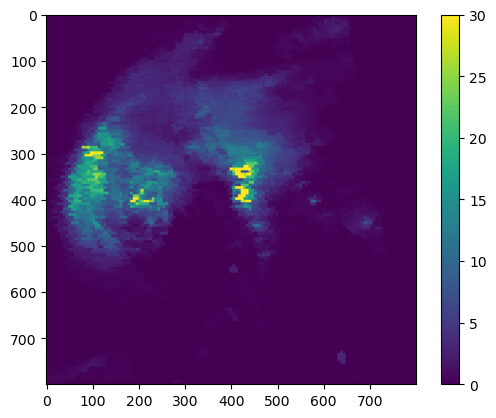

In [9]:
plt.imshow(res_cmorph.cmorph, vmax=30)
plt.colorbar()

In [10]:
import numpy as np
from pansat.products.satellite.gpm import merged_ir
from pansat.time import TimeRange

start_time = np.datetime64("2025-07-04T09:00:00")
end_time = np.datetime64("2025-07-04T12:00:00")
time_range = TimeRange(start_time, end_time)
recs = merged_ir.get(time_range)

Please enter your pansat user password:


 ········


In [5]:
from gprof_ir.retrieval import run_retrieval_multi
input_files = sorted([rec.local_path for rec in recs])

start_time = np.datetime64("2025-07-04T11:00:00")
end_time = np.datetime64("2025-07-04T12:00:00")
roi = (lon_min, lat_min, lon_max, lat_max)
results = run_retrieval_multi(
    input_files[0].parent,
    device="cuda:0",
    dtype="bfloat16",
    start_time=start_time,
    end_time=end_time,
    roi=roi
)

/home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[16:38:40] INFO     Found 2 files in                                                               ]8;id=13689018;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/gprof_ir/retrieval.py\retrieval.py]8;;\:]8;id=13689019;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/gprof_ir/retrieval.py#275\275]8;;\
                    /edata2/simon/satellite_data/gpm/merged_ir/merg_2025070412_4km-pixel.nc4.                      

/home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" 
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" 
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" 
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" 
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [6]:
import xarray as xr
results = xr.concat(results, dim="time")

In [60]:
lons, lats = area.get_lonlats()
res_gprof_ir = results.interp(longitude=lons[0], latitude=lats[..., 0])

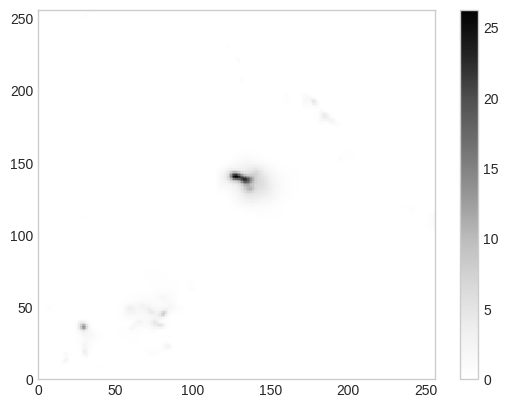

In [55]:
import matplotlib.pyplot as plt
plt.pcolormesh(results.surface_precip[3])
plt.colorbar()

In [9]:
import numpy as np
from pansat import TimeRange
from pansat.catalog import Index
from pansat.products.satellite.gpm import l1c_xcal2025n_tropics03_tms_parv804


start_time = np.datetime64("2025-07-04T00:00:00")
end_time = np.datetime64("2025-07-05T00:00:00")
recs = l1c_xcal2025n_tropics03_tms_parv804.get(TimeRange(start_time, end_time))

In [18]:
files

[PosixPath('/edata1/archive/GPM/1C_TROPICS03_ITE/2507/250704/1C.TROPICS03.TMS.XCAL2025-N.20250704-S005901-E023130.011744.PARV804.nc'),
 PosixPath('/edata1/archive/GPM/1C_TROPICS03_ITE/2507/250704/1C.TROPICS03.TMS.XCAL2025-N.20250704-S023131-E040401.011745.PARV804.nc'),
 PosixPath('/edata1/archive/GPM/1C_TROPICS03_ITE/2507/250704/1C.TROPICS03.TMS.XCAL2025-N.20250704-S040402-E053631.011746.PARV804.nc'),
 PosixPath('/edata1/archive/GPM/1C_TROPICS03_ITE/2507/250704/1C.TROPICS03.TMS.XCAL2025-N.20250704-S053632-E070901.011747.PARV804.nc'),
 PosixPath('/edata1/archive/GPM/1C_TROPICS03_ITE/2507/250704/1C.TROPICS03.TMS.XCAL2025-N.20250704-S070902-E084131.011748.PARV804.nc'),
 PosixPath('/edata1/archive/GPM/1C_TROPICS03_ITE/2507/250704/1C.TROPICS03.TMS.XCAL2025-N.20250704-S084132-E101401.011749.PARV804.nc'),
 PosixPath('/edata1/archive/GPM/1C_TROPICS03_ITE/2507/250704/1C.TROPICS03.TMS.XCAL2025-N.20250704-S101402-E114632.011750.PARV804.nc'),
 PosixPath('/edata1/archive/GPM/1C_TROPICS03_ITE/2507/2

In [15]:

ls -ltrh /edata1/archive/GPM/1C_TROPICS03_ITE/

total 108K
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2306/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2307/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2308/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2309/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2310/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2311/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2312/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2401/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2402/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2403/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2404/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2405/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2406/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2407/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2408/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2409/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2410/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2411/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2412/
drwxr-xr-x 1 10918 users 4.0K Sep 11  2025 2501/
drwxr-xr-

In [15]:
import argos

In [16]:
argos.__file__

'/home/simon/src/argus/src/argos/__init__.py'

In [16]:
from argos.data.dataset import ArgosDataset

ds = ArgosDataset(
    "/gdata2/simon/argus/training_data/"
)

KeyError: "'geo_sensor' not found in consolidated metadata."

In [ ]:
time

In [27]:
from pansat.environment import get_index
from pansat.catalog import Index
files = sorted(list(Path("/edata1/archive/GPM/1C_TROPICS03_ITE/2507/250704/").glob("*.nc")))
index = Index.index(l1c_xcal2025n_tropics03_tms_parv804, files)

In [28]:
roi = LonLatRect(lon_min, lat_min, lon_max, lat_max)
granules = index.find(roi=roi)

Granule(filename='1C.TROPICS03.TMS.XCAL2025-N.20250704-S101402-E114632.011750.PARV804.nc', start_time='2025-07-04 10:54:23.890000', end_time='2025-07-04 11:00:12.118000', primary_index_name='scans', primary_index_range='(1081, 1516)', secondary_index_name='pixels', secondary_index_range='(0, 81)')


(25.0, 35.0)

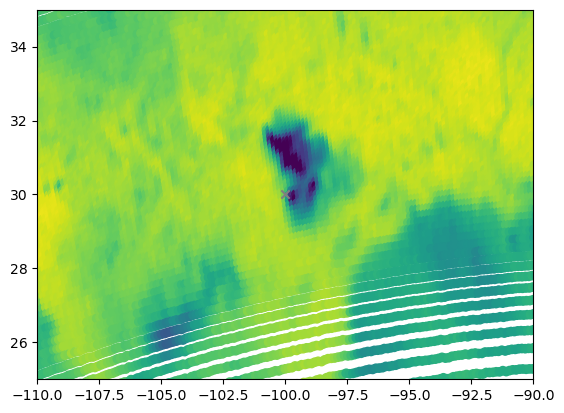

In [40]:
import matplotlib.pyplot as plt
from copy import copy
ind = 1
granule = copy(granules[ind])
start, end = granule.primary_index_range
granule.primary_index_range = (start - 130, end + 130)

data = granule.open()
lons = data.longitude_s3.data
lats = data.latitude_s3.data
valid = (-200 < lons) * (-200 < lats)
plt.scatter(lons[valid], lats[valid], c=data.tbs_s1.data[valid, 0], vmin=200)
plt.scatter(-100, 30, marker="x", c="grey")
print(granule)
plt.xlim(-110, -90)
plt.ylim(25, 35)

## GOES 19 Obs

In [41]:
from pansat.products.satellite.goes import l1b_goes_19_rad_c13_full_disk
time = granules[ind].time_range.start
goes_recs = l1b_goes_19_rad_c13_full_disk.get(granules[ind].time_range.start)

In [42]:
from satpy import Scene
files = [rec.local_path for rec in goes_recs]
scene = Scene(files)
scene.load(["C13"])
scene_r = scene.resample(area)
scene_r.save_dataset("C13", "goes_rgb_cs1.png")

[16:44:03] ERROR    Problem with                                                                     ]8;id=13689026;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/loading.py\loading.py]8;;\:]8;id=13689027;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/loading.py#106\106]8;;\
                    ['/home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/etc/reade               
                    rs/etm_l2_tif.yaml']                                                                           

           ERROR    while constructing a Python object                                               ]8;id=13689033;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/loading.py\loading.py]8;;\:]8;id=13689034;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/loading.py#107\107]8;;\
                    cannot find module 'satpy.readers.core.landsat' (No module named 'rioxarray')                  
                      in                                                                                           
                    "/home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/etc/reader               
                    s/etm_l2_tif.yaml", line 36, column 22                                                         

           WARNING  No filenames found for reader: jami_hrit                                     ]8;id=13689041;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py\yaml_reader.py]8;;\:]8;id=13689042;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py#273\273]8;;\

           WARNING  No filenames found for reader: hsaf_h5                                       ]8;id=13689047;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py\yaml_reader.py]8;;\:]8;id=13689048;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py#273\273]8;;\

           WARNING  No filenames found for reader: ahi_l1b_gridded_bin                           ]8;id=13689053;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py\yaml_reader.py]8;;\:]8;id=13689054;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py#273\273]8;;\

...

           WARNING  No filenames found for reader: ahi_hrit                                      ]8;id=13689647;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py\yaml_reader.py]8;;\:]8;id=13689648;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py#273\273]8;;\

           WARNING  No filenames found for reader: viirs_compact                                 ]8;id=13689653;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py\yaml_reader.py]8;;\:]8;id=13689654;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py#273\273]8;;\

           WARNING  No filenames found for reader: iasi_l2                                       ]8;id=13689659;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py\yaml_reader.py]8;;\:]8;id=13689660;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/readers/core/yaml_reader.py#273\273]8;;\

[16:44:04] INFO     Using default KDTree resampler                                                      ]8;id=13689667;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/resample/base.py\base.py]8;;\:]8;id=13689668;file:///home/simon/miniconda3/envs/argus/lib/python3.13/site-packages/satpy/resample/base.py#114\114]8;;\

['PNG']

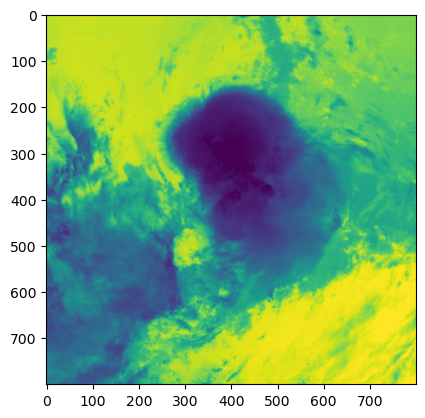

In [43]:
from PIL import Image
img = np.array(Image.open("goes_rgb_cs1.png"))
plt.imshow(img[..., 0])

In [44]:
from pansat.utils import resample_data
tms_obs = granule.open()[["longitude_s1", "tbs_s1", "latitude_s1"]].rename(
    tbs_s1="tbs",
    longitude_s1="longitude",
    latitude_s1="latitude"
)
tms_obs = resample_data(tms_obs, area, radius_of_influence=50e3)

## Scampr Precip

In [45]:
time

Timestamp('2025-07-04 10:54:23.890000')

In [47]:
import xarray as xr
res_scampr = xr.load_dataset("/gdata2/simon/argus/test_data/scampr/scampr_20250704110000.zarr/")
res_scampr = resample_data(res_scampr, area)
import xarray as xr
res_argos = xr.load_dataset("results_ana_g16/argos_20250704110000.nc")
res_argos = resample_data(res_argos, area)

/tmp/ipykernel_321469/2407397564.py:2: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  res_scampr = xr.load_dataset("/gdata2/simon/argus/test_data/scampr/scampr_20250704110000.zarr/")


In [48]:
import xarray as xr
res_argos = xr.load_dataset("results_ana/argos_20250704110000.nc")
res_argos = resample_data(res_argos, area)

In [49]:
import xarray as xr
res_argos_geo = xr.load_dataset("results_geo/argos_20250704110000.nc")
res_argos_geo = resample_data(res_argos_geo, area)

## MRMS Precip

In [50]:
from pansat.products.ground_based.mrms import radar_quality_index, precip_rate

time = np.datetime64("2025-07-04T11:00:00")
rec = precip_rate.get(time)[0]
mrms_precip = rec.open()
rec = radar_quality_index.get(time)[0]
rqi = rec.open()
res_mrms = xr.merge([mrms_precip, rqi])
res_mrms = resample_data(res_mrms, area)

/tmp/ipykernel_321469/3740162639.py:8: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  res_mrms = xr.merge([mrms_precip, rqi])
/tmp/ipykernel_321469/3740162639.py:8: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  res_mrms = xr.merge([mrms_precip, rqi])
/tmp/ipykernel_321469/3740162639.py:8: FutureWarning: In a future version of xarray th

In [51]:
import matplotlib as mpl
import seaborn as sns
sns.reset_orig()
mpl.style.use("seaborn-v0_8-whitegrid")

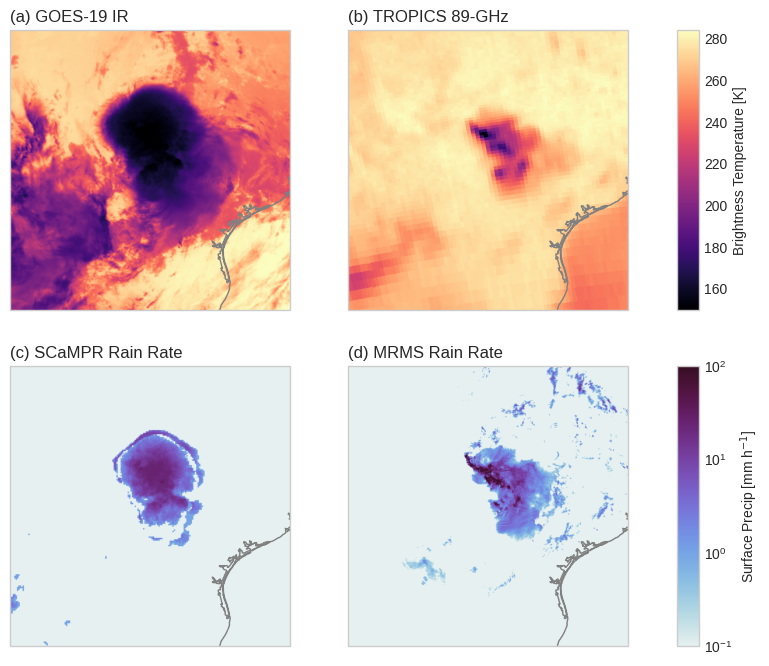

In [52]:
import cmocean
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LogNorm

fig = plt.figure(figsize=(9, 8))
gs = GridSpec(2, 3, width_ratios=[1.0, 1.0, 0.075])
norm = LogNorm(1e-1, 1e2)

cmap_precip = "cmo.dense"
crs = area.to_cartopy_crs()
ext = area.area_extent
ext = (ext[0], ext[2], ext[1], ext[3])

ax = fig.add_subplot(gs[0, 0], projection=crs)
ax.imshow(img[..., 0], cmap="magma", extent=ext)
ax.set_title("(a) GOES-19 IR", loc="left")
ax.coastlines(color="grey")

ax = fig.add_subplot(gs[0, 1], projection=crs)
m_tbs = ax.imshow(tms_obs.tbs[..., 0], cmap="magma", extent=ext)
ax.set_title("(b) TROPICS 89-GHz", loc="left")
ax.coastlines(color="grey")

ax = fig.add_subplot(gs[1, 0], projection=crs)
ax.imshow(np.maximum(res_scampr.surface_precip, 1e-3), cmap=cmap_precip, norm=norm, extent=ext)
ax.set_title("(c) SCaMPR Rain Rate", loc="left")
ax.coastlines(color="grey")

ax = fig.add_subplot(gs[1, 1], projection=crs)
m_pr = ax.imshow(np.maximum(res_mrms.precip_rate, 1e-3), cmap=cmap_precip, norm=norm, extent=ext)
ax.set_title("(d) MRMS Rain Rate", loc="left")
ax.coastlines(color="grey")

cax_tbs = fig.add_subplot(gs[0, -1])
plt.colorbar(m_tbs, label="Brightness Temperature [K]", cax=cax_tbs)

cax_pr = fig.add_subplot(gs[1, -1])
plt.colorbar(m_pr, label="Surface Precip [mm h$^{-1}$]", cax=cax_pr)

In [59]:
sp_argos.shape
lons.shape

(435, 81)

0.5504640136680564 19.336117 25.296442
0.6000915558921628 19.802094868738543 -44.94986380381661


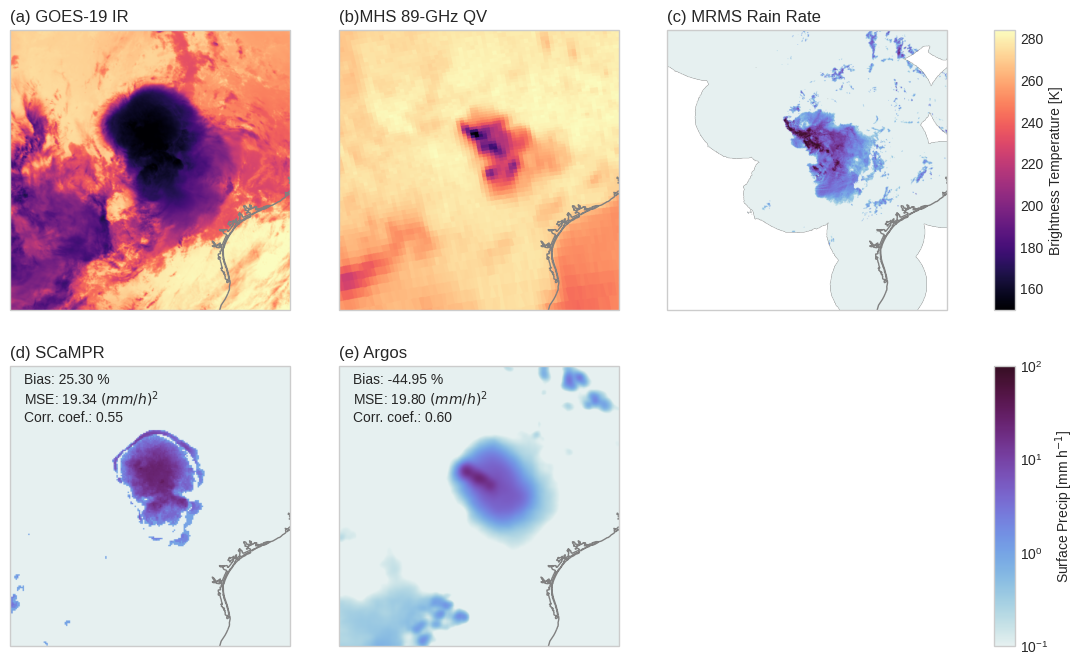

In [63]:
import cmocean
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LogNorm

fig = plt.figure(figsize=(13, 8))
gs = GridSpec(2, 4, width_ratios=[1.0, 1.0, 1.0, 0.075])
norm = LogNorm(1e-1, 1e2)

cmap_precip = "cmo.dense"
crs = area.to_cartopy_crs()
ext = area.area_extent
ext = (ext[0], ext[2], ext[1], ext[3])

ax = fig.add_subplot(gs[0, 0], projection=crs)
ax.imshow(img[..., 0], cmap="magma", extent=ext)
ax.set_title("(a) GOES-19 IR", loc="left")
ax.coastlines(color="grey")

ax = fig.add_subplot(gs[0, 1], projection=crs)
m_tbs = ax.imshow(tms_obs.tbs[..., 0], cmap="magma", extent=ext)
ax.set_title("(b)MHS 89-GHz QV", loc="left")
ax.coastlines(color="grey")

rqi = res_mrms.radar_quality_index.data
sp_mrms = res_mrms.precip_rate.data.copy()
sp_mrms[~(0.5 < rqi)] = np.nan
ax = fig.add_subplot(gs[0, 2], projection=crs)
m_pr = ax.imshow(np.maximum(sp_mrms, 1e-3), cmap=cmap_precip, norm=norm, extent=ext)
ax.set_title("(c) MRMS Rain Rate", loc="left")
ax.coastlines(color="grey")


sp_scampr = res_scampr.surface_precip.data
ax_scampr = fig.add_subplot(gs[1, 0], projection=crs)
ax_scampr.imshow(np.maximum(sp_scampr, 1e-3), cmap=cmap_precip, norm=norm, extent=ext)
ax_scampr.set_title("(d) SCaMPR", loc="left")
ax_scampr.coastlines(color="grey")


#sp_argos = res_argos.surface_precip.data
sp_argos = res_gprof_ir.surface_precip.data[2]
ax_argos = fig.add_subplot(gs[1, 1], projection=crs)
ax_argos.imshow(np.maximum(sp_argos, 1e-3), cmap=cmap_precip, norm=norm, extent=ext)
ax_argos.set_title("(e) Argos", loc="left")
ax_argos.coastlines(color="grey")
sp_mrms = res_mrms.precip_rate.data

sp_mrms = res_mrms.precip_rate.data
rqi = res_mrms.radar_quality_index.data
valid = np.isfinite(sp_mrms) * np.isfinite(sp_scampr) *  np.isfinite(sp_argos) * (0.5 < rqi)

corr_scampr = np.corrcoef(sp_mrms[valid], sp_scampr[valid])[0, 1]
mse_scampr = np.mean(np.square(sp_mrms[valid] - sp_scampr[valid]))
bias_scampr = 100.0 * np.mean(sp_scampr[valid] - sp_mrms[valid]) / np.mean(sp_mrms[valid])

corr_argos = np.corrcoef(sp_mrms[valid], sp_argos[valid])[0, 1]
mse_argos = np.mean(np.square(sp_mrms[valid] - sp_argos[valid]))
bias_argos = 100.0 * np.mean(sp_argos[valid] - sp_mrms[valid]) / np.mean(sp_mrms[valid])

ax_scampr.text(
    0.05, 0.8, f"Bias: {bias_scampr:.2f} %\nMSE: {mse_scampr:.2f} $(mm/h)^2$\nCorr. coef.: {corr_scampr:.2f}",
    transform=ax_scampr.transAxes
)
ax_argos.text(
    0.05, 0.8, f"Bias: {bias_argos:.2f} %\nMSE: {mse_argos:.2f} $(mm/h)^2$\nCorr. coef.: {corr_argos:.2f}",
    transform=ax_argos.transAxes
)
    
print(corr_scampr, mse_scampr, bias_scampr)
print(corr_argos, mse_argos, bias_argos)

cax_tbs = fig.add_subplot(gs[0, -1])
plt.colorbar(m_tbs, label="Brightness Temperature [K]", cax=cax_tbs)

cax_pr = fig.add_subplot(gs[1, -1])
plt.colorbar(m_pr, label="Surface Precip [mm h$^{-1}$]", cax=cax_pr)

## Temporal Evolution

In [39]:
from pansat.utils import resample_data_binned
from pansat.products.ground_based.mrms import radar_quality_index, precip_rate

times = [
    np.datetime64("2025-07-04T11:00:00"),
    np.datetime64("2025-07-04T11:20:00"),
    np.datetime64("2025-07-04T11:40:00")
]
res_mrms = []
for time in times:
    rec = precip_rate.get(time)[0]
    mrms_precip = rec.open()
    rec = radar_quality_index.get(time)[0]
    rqi = rec.open()
    res_mrms_t = xr.merge([mrms_precip, rqi])
    res_mrms.append(resample_data(resample_data_binned(res_mrms_t, area_5), area))
res_mrms = xr.concat(res_mrms, dim="time")

/tmp/ipykernel_1069899/3364336150.py:15: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  res_mrms_t = xr.merge([mrms_precip, rqi])
/tmp/ipykernel_1069899/3364336150.py:15: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  res_mrms_t = xr.merge([mrms_precip, rqi])
/tmp/ipykernel_1069899/3364336150.py:15: FutureWarning: In a future version of

In [40]:
import xarray as xr
res_scampr = xr.concat([
    resample_data(xr.load_dataset("/gdata2/simon/argus/test_data/scampr/scampr_20250704110000.zarr/"), area),
    resample_data(xr.load_dataset("/gdata2/simon/argus/test_data/scampr/scampr_20250704113000.zarr"), area),
    resample_data(xr.load_dataset("/gdata2/simon/argus/test_data/scampr/scampr_20250704115000.zarr/"), area),
], dim="time")


/tmp/ipykernel_1069899/281791117.py:3: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  resample_data(xr.load_dataset("/gdata2/simon/argus/test_data/scampr/scampr_20250704110000.zarr/"), area),
/tmp/ipykernel_1069899/281791117.py:4: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadat

In [50]:
import xarray as xr
res_argos = xr.concat([
    resample_data(xr.load_dataset("results_geo/argos_20250704110000.nc"), area),
    resample_data(xr.load_dataset("results_ana/argos_20250704112000.nc"), area),
    resample_data(xr.load_dataset("results_ana/argos_20250704114000.nc"), area),
],
                     dim="time")

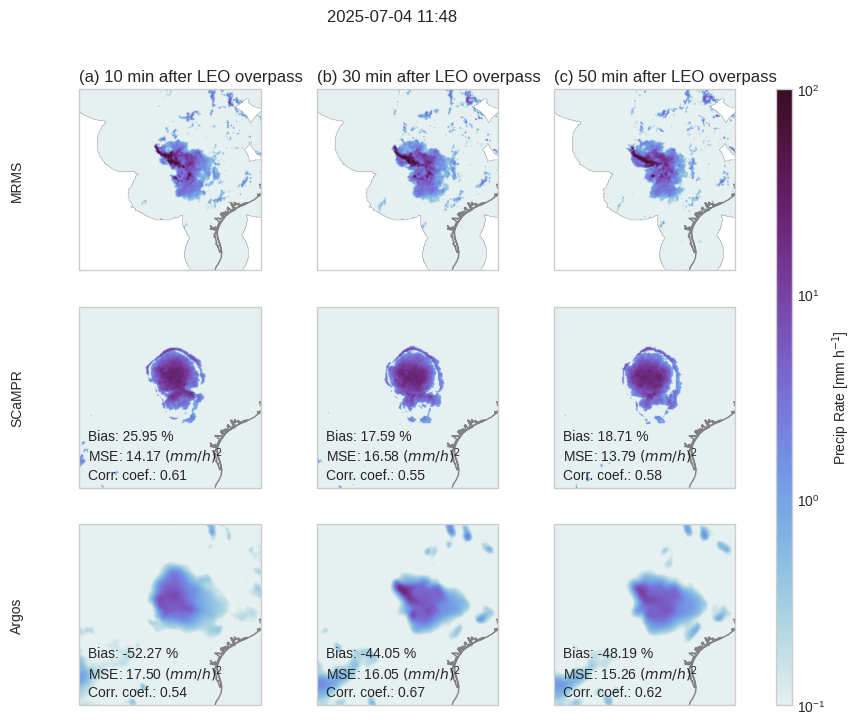

In [51]:
import cmocean
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LogNorm

fig = plt.figure(figsize=(10, 8))
gs = GridSpec(3, 5, width_ratios=[0.1, 1.0, 1.0, 1.0, 0.075])
norm = LogNorm(1e-1, 1e2)

cmap_precip = "cmo.dense"
crs = area.to_cartopy_crs()
ext = area.area_extent
ext = (ext[0], ext[2], ext[1], ext[3])
cmap_precip = "cmo.dense"

titles = [
    "(a) 10 min after LEO overpass",
    "(b) 30 min after LEO overpass",
    "(c) 50 min after LEO overpass",
]

for time in range(3):

    if time == 0:
        for ind, label in enumerate(["MRMS", "SCaMPR", "Argos"]):
            ax = fig.add_subplot(gs[ind, 0])
            ax.set_axis_off()
            ax.text(0, 0, s=label, rotation=90, ha="center", va="center")
            ax.set_ylim(-2, 2)

    sp_mrms = np.maximum(res_mrms.precip_rate.data[time].copy(), 1e-3)
    rqi = res_mrms.radar_quality_index.data[time]
    sp_mrms[~(0.5 < rqi)] = np.nan
    sp_scampr = np.maximum(res_scampr.surface_precip.data[time].data, 1e-3)
    sp_argos = np.maximum(res_argos.surface_precip.data[time].data, 1e-3)
    valid = np.isfinite(sp_mrms) * np.isfinite(sp_scampr) * np.isfinite(sp_argos) * (0.5 < rqi)
    
    ax = fig.add_subplot(gs[0, 1 + time], projection=crs)
    ax.imshow(sp_mrms, cmap=cmap_precip, extent=ext, norm=norm)
    ax.coastlines(color="grey")
    ax.set_title(titles[time], loc="left")
    
    ax_scampr = fig.add_subplot(gs[1, 1 + time], projection=crs)
    ax_scampr.imshow(sp_scampr, cmap=cmap_precip, extent=ext, norm=norm)
    ax_scampr.coastlines(color="grey")
    
    ax_argos = fig.add_subplot(gs[2, 1 + time], projection=crs)
    m = ax_argos.imshow(sp_argos, cmap=cmap_precip, extent=ext, norm=norm)
    ax_argos.coastlines(color="grey")

    sp_mrms = res_mrms.precip_rate.data[time]
    rqi = res_mrms.radar_quality_index.data[time]
    valid = np.isfinite(sp_mrms) * np.isfinite(sp_scampr) *  np.isfinite(sp_argos) * (0.5 < rqi)
    
    corr_scampr = np.corrcoef(sp_mrms[valid], sp_scampr[valid])[0, 1]
    mse_scampr = np.mean(np.square(sp_mrms[valid] - sp_scampr[valid]))
    bias_scampr = 100.0 * np.mean(sp_scampr[valid] - sp_mrms[valid]) / np.mean(sp_mrms[valid])
    
    corr_argos = np.corrcoef(sp_mrms[valid], sp_argos[valid])[0, 1]
    mse_argos = np.mean(np.square(sp_mrms[valid] - sp_argos[valid]))
    bias_argos = 100.0 * np.mean(sp_argos[valid] - sp_mrms[valid]) / np.mean(sp_mrms[valid])
    
    ax_scampr.text(
        0.05, 0.05, f"Bias: {bias_scampr:.2f} %\nMSE: {mse_scampr:.2f} $(mm/h)^2$\nCorr. coef.: {corr_scampr:.2f}",
        transform=ax_scampr.transAxes
    )
    ax_argos.text(
        0.05, 0.05, f"Bias: {bias_argos:.2f} %\nMSE: {mse_argos:.2f} $(mm/h)^2$\nCorr. coef.: {corr_argos:.2f}",
        transform=ax_argos.transAxes
    )
    
cax = fig.add_subplot(gs[:, -1])
fig.suptitle("2025-07-04 11:48")
plt.colorbar(m, cax=cax, label="Precip Rate [mm h$^{-1}$]")

In [158]:
import pandas as pd
from tqdm import tqdm
from ipwgml.data import get_local_files

#sizes = {}
domain_df = []
split_df = []
geometry_df = []

sizes_gmi = []
sizes_geo = []
sizes_geo_t = []
sizes_geo_ir = []
sizes_geo_ir_t = []
sizes_anc = []
sizes_target = []
n_files = []


sizes = {}

for geometry in ["gridded", "on_swath"]:
    for domain in tqdm(domains):
        for split in splits:
            source_sizes = sizes.setdefault(domain, {}).setdefault(split, {})

            print(geometry, split)
                
            files = get_local_files("satrain", "gmi", geometry, split, domain=domain)
            
            domain_df.append(domain)
            split_df.append(split)
            geometry_df.append(geometry)

            n_files.append(len(files["gmi"]))
    
            size_gmi = 0
            for path in files["gmi"]:
                size_gmi += Path(path).stat().st_size
            sizes_gmi.append(size_gmi)
                
            size_geo = 0
            for path in files["geo"]:
                size_geo += Path(path).stat().st_size
            sizes_geo.append(size_geo)
            
            size_geo_t = 0
            for path in files["geo_t"]:
                size_geo_t += Path(path).stat().st_size
            sizes_geo_t.append(size_geo_t)
                
            size_geo_ir = 0
            for path in files["geo_ir"]:
                size_geo_ir += Path(path).stat().st_size
            sizes_geo_ir.append(size_geo_ir)
                
            size_geo_ir_t = 0
            for path in files["geo_ir_t"]:
                size_geo_ir_t += Path(path).stat().st_size
            sizes_geo_ir_t.append(size_geo_ir_t)
            
            size_anc = 0
            for path in files["ancillary"]:
                size_anc += Path(path).stat().st_size
            sizes_anc.append(size_anc)
                
            size_target = 0
            for path in files["target"]:
                size_target += Path(path).stat().st_size
            sizes_target.append(size_target)
    
df = pd.DataFrame({
    "domain": domain_df,
    "split": split_df,
    "geometry": geometry_df,
    "geo_ir": sizes_geo_ir,
    "geo": sizes_geo,
    "gmi": sizes_gmi,
    "geo_ir_t": sizes_geo_ir_t,
    "ancillary": sizes_anc,
    "geo_t": sizes_geo_t,
    "target": sizes_target,
    #"n_files": n_files
})
df["gmi"] /= 1e9
df["geo"] /= 1e9
df["geo_t"] /= 1e9
df["geo_ir"] /= 1e9
df["geo_ir_t"] /= 1e9
df["ancillary"] /= 1e9
df["target"] /= 1e9
sizes[geometry] = df
    

 33%|██████████████████████████████████▋                                                                     | 1/3 [00:00<00:00,  7.23it/s]

gridded testing
gridded testing


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:01<00:00,  1.65it/s]


gridded testing


  0%|                                                                                                                | 0/3 [00:00<?, ?it/s]

on_swath testing
on_swath testing


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00,  4.54it/s]

on_swath testing


In [159]:
df_test_os = df.loc[(df.geometry == "on_swath") * (df.split == "testing")]
df_test_gr = df.loc[(df.geometry == "gridded") * (df.split == "testing")]

In [160]:
df

,domain,split,geometry,geo_ir,geo,gmi,geo_ir_t,ancillary,geo_t,target
0,austria,testing,gridded,0.231538,0.455540,0.114015,0.264870,0.727967,1.607913,0.016787
1,conus,testing,gridded,15.353987,38.581460,4.499372,19.291541,48.833053,158.329131,2.280263
2,korea,testing,gridded,0.447347,1.263522,0.228456,0.551935,0.796398,5.417712,0.058702
3,austria,testing,on_swath,0.278990,0.471187,0.288413,0.341616,0.642457,1.325552,0.264938
4,conus,testing,on_swath,4.097302,6.669123,4.220969,5.013570,8.917766,18.240785,2.269397
5,korea,testing,on_swath,0.525274,1.038420,0.545072,0.685240,1.129487,3.591518,0.769937


In [161]:
df_test_os = df_test_os.melt(id_vars=["domain", "geometry", "split"], var_name="source", value_name="size") 
df_test_gr = df_test_gr.melt(id_vars=["domain", "geometry", "split"], var_name="source", value_name="size") 

In [162]:
df_test_os

,domain,geometry,split,source,size
0,austria,on_swath,testing,geo_ir,0.278990
1,conus,on_swath,testing,geo_ir,4.097302
2,korea,on_swath,testing,geo_ir,0.525274
3,austria,on_swath,testing,geo,0.471187
4,conus,on_swath,testing,geo,6.669123
5,korea,on_swath,testing,geo,1.038420
6,austria,on_swath,testing,gmi,0.288413
7,conus,on_swath,testing,gmi,4.220969
8,korea,on_swath,testing,gmi,0.545072
9,austria,on_swath,testing,geo_ir_t,0.341616


In [163]:
df_val_os

,subset,geometry,split,source,size
0,xs,on_swath,validation,ancillary,0.048703
1,s,on_swath,validation,ancillary,0.199908
2,m,on_swath,validation,ancillary,0.680057
3,l,on_swath,validation,ancillary,2.187920
4,xl,on_swath,validation,ancillary,4.782186
5,xs,on_swath,validation,geo,0.028616
6,s,on_swath,validation,geo,0.119653
7,m,on_swath,validation,geo,0.406423
8,l,on_swath,validation,geo,1.314612
9,xl,on_swath,validation,geo,2.873064


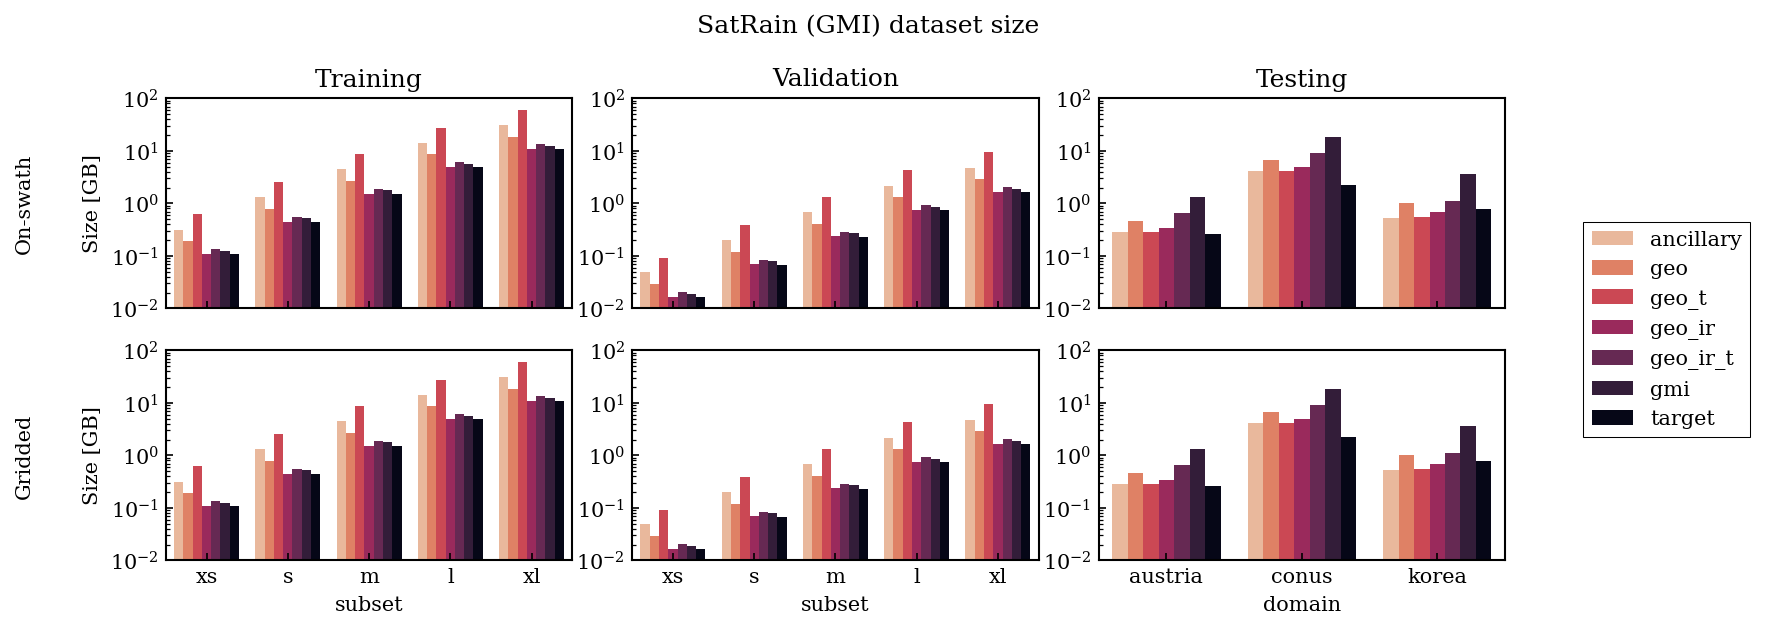

In [183]:
import seaborn as sns
from matplotlib.gridspec import GridSpec
from ipwgml.plotting import cmap_precip, cmap_tbs

palette = [cmap_tbs(val) for val in np.linspace(0, 1, 8)[:-1][::-1]]

gs = GridSpec(2, 5, width_ratios=[0.2, 1.0, 1.0, 1.0, 0.5])
fig = plt.figure(figsize=(15, 4))

ax = fig.add_subplot(gs[0, 0])
ax.set_axis_off()
ax.text(0, 0, "On-swath", rotation=90, ha="center", va="center")
ax.set_ylim(-2, 2)

ax = fig.add_subplot(gs[0, 1])
sns.barplot(df_tr_os, x="subset", hue="source", y="size", legend=True, palette=palette)
ax.set_yscale("log")
ax.set_ylabel("Size [GB]")
ax.set_ylim(1e-2, 1e2)
ax.set_xlabel("")
ax.set_xticklabels([])
handles, labels = ax.get_legend_handles_labels()
ax.legend_.remove()
ax.set_title("Training", loc="center")

ax = fig.add_subplot(gs[0, 2])
sns.barplot(df_val_os, x="subset", hue="source", y="size", legend=False, palette=palette)
ax.set_yscale("log")
ax.set_ylabel(None)
ax.set_ylim(1e-2, 1e2)
ax.set_xlabel("")
ax.set_xticklabels([])
ax.set_title("Validation", loc="center")

ax = fig.add_subplot(gs[0, 3])
sns.barplot(df_test_os, x="domain", hue="source", y="size", legend=False, palette=palette)
ax.set_yscale("log")
ax.set_ylabel("Size [GB]")
ax.set_ylabel(None)
ax.set_ylim(1e-2, 1e2)
ax.set_xlabel("")
ax.set_xticklabels([])
ax.set_title("Testing", loc="center")

ax = fig.add_subplot(gs[1, 0])
ax.set_axis_off()
ax.text(0, 0, "Gridded", rotation=90, ha="center", va="center")
ax.set_ylim(-2, 2)

ax = fig.add_subplot(gs[1, 1])
sns.barplot(df_tr_os, x="subset", hue="source", y="size", legend=False, palette=palette)
ax.set_yscale("log")
ax.set_ylabel("Size [GB]")
ax.set_ylim(1e-2, 1e2)

ax = fig.add_subplot(gs[1, 2])
sns.barplot(df_val_os, x="subset", hue="source", y="size", legend=False, palette=palette)
ax.set_yscale("log")
ax.set_ylabel(None)
ax.set_ylim(1e-2, 1e2)

ax = fig.add_subplot(gs[1, 3])
sns.barplot(df_test_os, x="domain", hue="source", y="size", legend=False, palette=palette)
ax.set_yscale("log")
ax.set_ylabel("Size [GB]")
ax.set_ylabel(None)
ax.set_ylim(1e-2, 1e2)

fig.suptitle("SatRain (GMI) dataset size", y=1.02)

lax = fig.add_subplot(gs[:, -1])
lax.set_axis_off()
lax.legend(handles=handles, labels=labels, loc="center")

In [43]:
df

,domain,split,geometry,ancillary,geo,geo_t,geo_ir,geo_ir_t,gmi,target,n_files
0,austria,testing,gridded,0.727967,0.455540,1.607913,231538205,0.264870,0.114015,0.016787,397
1,conus,testing,gridded,48.833053,38.581460,158.329131,15353986766,19.291541,4.499372,2.280263,2912
2,korea,testing,gridded,0.796398,1.263522,5.417712,447346978,0.551935,0.228456,0.058702,600
3,austria,testing,on_swath,0.642457,0.471187,1.325552,278989777,0.341616,0.288413,0.264938,397
4,conus,testing,on_swath,8.917766,6.669123,18.240785,4097302328,5.013570,4.220969,2.269397,2912
5,korea,testing,on_swath,1.129487,1.038420,3.591518,525274480,0.685240,0.545072,0.769937,600


In [51]:
df_test = df.melt(id_vars=["domain", "split", "geometry"], var_name="source")

In [31]:
df_tr = df
df_val = df.groupby("subset").sum().reindex(["xs", "s", "m", "l", "xl"])

In [55]:
df_test

,domain,split,geometry,source,value
0,austria,testing,gridded,ancillary,7.279666e-01
1,conus,testing,gridded,ancillary,4.883305e+01
2,korea,testing,gridded,ancillary,7.963982e-01
3,austria,testing,on_swath,ancillary,6.424574e-01
4,conus,testing,on_swath,ancillary,8.917766e+00
5,korea,testing,on_swath,ancillary,1.129487e+00
6,austria,testing,gridded,geo,4.555403e-01
7,conus,testing,gridded,geo,3.858146e+01
8,korea,testing,gridded,geo,1.263522e+00
9,austria,testing,on_swath,geo,4.711867e-01


<Axes: xlabel='domain', ylabel='value'>

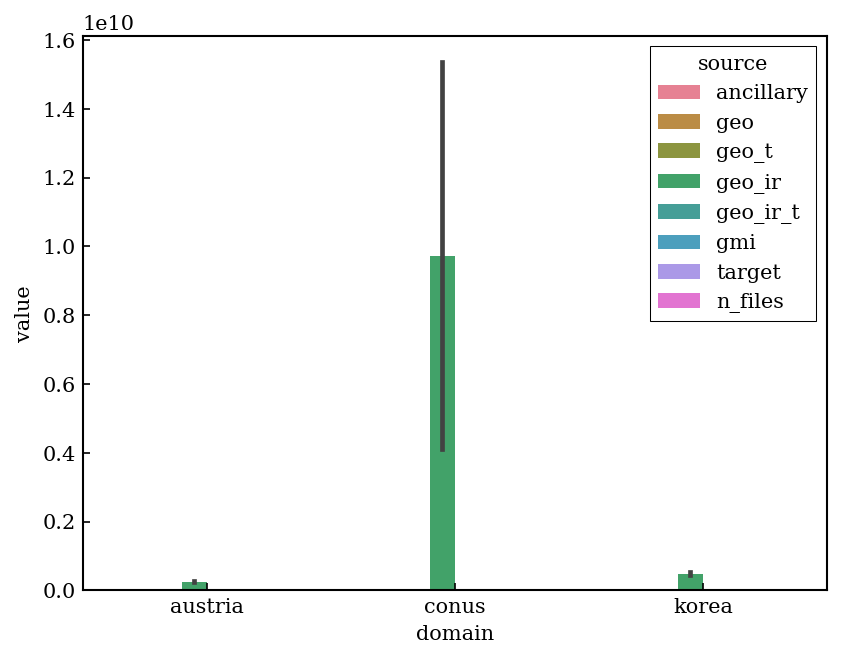

In [58]:
import seaborn as sns
sns.barplot(df_test, x="domain", hue="source", y="value")

Text(0, 0.5, 'Size [GB]')

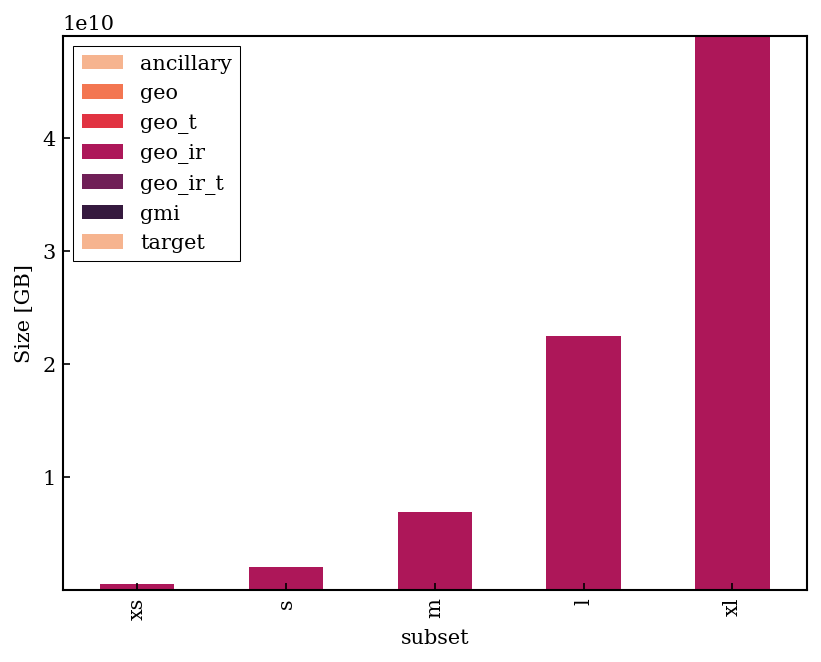

In [32]:
import seaborn as sns
ax = df_tr.plot.bar(stacked=True, color=palette)
ax.set_ylabel("Size [GB]")
#ax.set_yscale("log")


In [136]:
df

,split,ancillary,geo,geo_ir,gmi,target
subset,,,,,,
l,trainingvalidationtesting,56.529151,178.834813,20.320597,9.166267,3.682998
m,trainingvalidationtesting,17.457548,55.335297,6.280542,2.838380,1.138172
s,trainingvalidationtesting,5.110142,16.266929,1.837044,0.834445,0.330815
xl,trainingvalidationtesting,123.281198,391.031536,44.420135,20.040395,8.047234
xs,trainingvalidationtesting,1.222855,3.904446,0.435882,0.199747,0.079996


NameError: name 'training' is not defined